# FTWP Chapter 6 — Review and Exercises

This notebook consolidates the **six non-capstone tasks** for FTWP Chapter 6:
three review exercises and three regular exercises. The problem statements are
paraphrased from the CPF exercise sheet. Numerical parameters are stated where
the source task leaves them open.

The notebook is designed to run from top to bottom in Google Colab or a standard
Python/Jupyter environment.

In [1]:
%matplotlib inline

## Review exercises

### 1. CRR parameters

For $\Delta t=T/m$,

$$u=e^{\sigma\sqrt{\Delta t}},\quad d=1/u,\quad
q=\frac{e^{r\Delta t}-d}{u-d},\quad df=e^{-r\Delta t}.$$

### 2. One-step backward induction

The current derivative value is the discounted risk-neutral conditional
expectation of the two next-node values.

### 3. Risk-neutral GBM mean

Under $Q$, $E_Q[S_T]=S_0e^{rT}$. I verify this with full simulated paths.

In [2]:
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.random import default_rng
from scipy.stats import norm

S0, K, r, sigma, T = 36.0, 40.0, 0.06, 0.20, 1.0
m = 50
dt = T / m
u = math.exp(sigma * math.sqrt(dt))
d = 1.0 / u
q = (math.exp(r * dt) - d) / (u - d)
df = math.exp(-r * dt)

next_values = np.array([3.0, 7.0])  # Up-node and Down-node derivative values
one_step_value = df * (q * next_values[0] + (1.0 - q) * next_values[1])

M_paths, I_paths = 100, 30_000
rng = default_rng(100)
Z = rng.standard_normal((M_paths, I_paths))
dt_paths = T / M_paths
S = np.empty((M_paths + 1, I_paths))
S[0] = S0
for t in range(1, M_paths + 1):
    S[t] = S[t - 1] * np.exp(
        (r - 0.5 * sigma**2) * dt_paths + sigma * math.sqrt(dt_paths) * Z[t - 1]
    )

simulated_mean = S[-1].mean()
theoretical_mean = S0 * math.exp(r * T)

print("u, d, q, df:", u, d, q, df)
print("One-step value:", one_step_value)
print("Simulated E_Q[ST]:", simulated_mean)
print("Theoretical S0 exp(rT):", theoretical_mean)

u, d, q, df: 1.0286880693018583 0.9721119840328972 0.5141525101445626 0.9988007197120864
One-step value: 4.9374614492879445
Simulated E_Q[ST]: 38.25612062659314
Theoretical S0 exp(rT): 38.22611567563295


## Regular exercises

### 4. European put convergence

Price a European put with increasing CRR step counts and compare with the
Black-Scholes value.

### 5. Least-Squares Monte Carlo for an American put

Regress only on in-the-money paths. The boundary diagnostic below is a
threshold-style empirical estimate: at each date it records the largest stock
price among simulated paths for which the fitted policy selects immediate
exercise. It is not an exact continuous-time free boundary.

### 6. CRR versus LSM

Use the same contract parameters and compare the American values.

,m,CRR European put,Black-Scholes,Absolute error
0,10,3.833428,3.844308,0.010880
1,25,3.842172,3.844308,0.002135
2,50,3.839611,3.844308,0.004697
3,100,3.848396,3.844308,0.004088
4,250,3.843745,3.844308,0.000563
5,500,3.843591,3.844308,0.000717
6,1000,3.844645,3.844308,0.000337


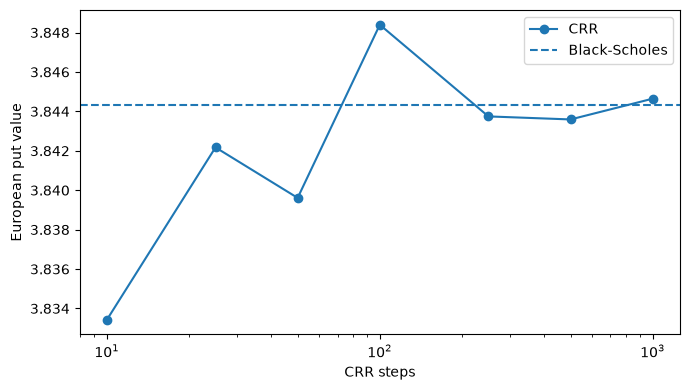

In [3]:
def bs_put(S0, K, r, sigma, T):
    d1 = (math.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)
    return K * math.exp(-r * T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)

def crr_put(S0, K, r, sigma, T, m, american=False):
    dt = T / m
    u = math.exp(sigma * math.sqrt(dt))
    d = 1.0 / u
    q = (math.exp(r * dt) - d) / (u - d)
    df = math.exp(-r * dt)
    j = np.arange(m + 1)
    ST = S0 * u ** (m - j) * d**j
    V = np.maximum(K - ST, 0.0)
    for step in range(m, 0, -1):
        continuation = df * (q * V[:-1] + (1.0 - q) * V[1:])
        if american:
            j = np.arange(step)
            St = S0 * u ** ((step - 1) - j) * d**j
            V = np.maximum(K - St, continuation)
        else:
            V = continuation
    return float(V[0])

bs_value = bs_put(S0, K, r, sigma, T)
m_grid = np.array([10, 25, 50, 100, 250, 500, 1000])
convergence = pd.DataFrame(
    {
        "m": m_grid,
        "CRR European put": [crr_put(S0, K, r, sigma, T, int(x)) for x in m_grid],
    }
)
convergence["Black-Scholes"] = bs_value
convergence["Absolute error"] = (convergence["CRR European put"] - bs_value).abs()
display(convergence)

plt.figure(figsize=(7, 4))
plt.plot(convergence["m"], convergence["CRR European put"], marker="o", label="CRR")
plt.axhline(bs_value, linestyle="--", label="Black-Scholes")
plt.xscale("log")
plt.xlabel("CRR steps")
plt.ylabel("European put value")
plt.legend()
plt.tight_layout()
plt.show()

CRR American put (1000 steps): 4.486837152443311
LSM American put: 4.484293961796267
Absolute difference: 0.0025431906470441135
Time-zero intrinsic value: 4.0
Time-zero continuation estimate: 4.484293961796267


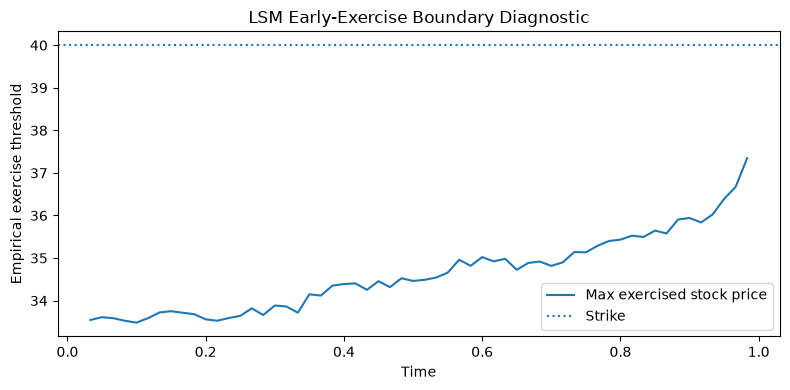

In [4]:
def simulate_gbm_paths(S0, r, sigma, T, M, I, seed):
    rng = default_rng(seed)
    dt = T / M
    Z = rng.standard_normal((M, I))
    S = np.empty((M + 1, I))
    S[0] = S0
    for t in range(1, M + 1):
        S[t] = S[t - 1] * np.exp(
            (r - 0.5 * sigma**2) * dt + sigma * math.sqrt(dt) * Z[t - 1]
        )
    return S

def lsm_american_put(S, K, r, T, degree=3):
    M = S.shape[0] - 1
    dt = T / M
    df = math.exp(-r * dt)
    h = np.maximum(K - S, 0.0)
    V = h[-1].copy()
    exercise = np.zeros_like(h, dtype=bool)

    for t in range(M - 1, 0, -1):
        itm = h[t] > 0.0
        x = S[t, itm]
        y = df * V[itm]
        if x.size >= degree + 1:
            coeff = np.polynomial.polynomial.polyfit(x, y, degree)
            continuation = np.polynomial.polynomial.polyval(S[t], coeff)
            exercise_now = itm & (h[t] > continuation)
        else:
            exercise_now = np.zeros(S.shape[1], dtype=bool)
        V = np.where(exercise_now, h[t], df * V)
        exercise[t] = exercise_now

    continuation_0 = df * V.mean()
    intrinsic_0 = max(K - float(S[0, 0]), 0.0)
    price = max(intrinsic_0, continuation_0)

    # For a put, the empirical exercise region is expected below a threshold.
    # The maximum exercised S at each date is a direct threshold-style summary.
    boundary = np.full(M + 1, np.nan)
    exercise_count = np.zeros(M + 1, dtype=int)
    for t in range(1, M):
        mask = exercise[t]
        exercise_count[t] = int(mask.sum())
        if mask.any():
            boundary[t] = float(S[t, mask].max())

    return {
        "price": float(price),
        "continuation_0": float(continuation_0),
        "intrinsic_0": float(intrinsic_0),
        "exercise": exercise,
        "boundary": boundary,
        "exercise_count": exercise_count,
    }

M_lsm, I_lsm = 60, 40_000
S_lsm = simulate_gbm_paths(S0, r, sigma, T, M_lsm, I_lsm, seed=100)
lsm = lsm_american_put(S_lsm, K, r, T, degree=3)
crr_american = crr_put(S0, K, r, sigma, T, m=1000, american=True)

print("CRR American put (1000 steps):", crr_american)
print("LSM American put:", lsm["price"])
print("Absolute difference:", abs(lsm["price"] - crr_american))
print("Time-zero intrinsic value:", lsm["intrinsic_0"])
print("Time-zero continuation estimate:", lsm["continuation_0"])

time_grid = np.arange(M_lsm + 1) * (T / M_lsm)
plt.figure(figsize=(8, 4))
plt.plot(time_grid, lsm["boundary"], label="Max exercised stock price")
plt.axhline(K, linestyle=":", label="Strike")
plt.xlabel("Time")
plt.ylabel("Empirical exercise threshold")
plt.title("LSM Early-Exercise Boundary Diagnostic")
plt.legend()
plt.tight_layout()
plt.show()

CRR is deterministic for a chosen tree size; LSM has simulation and regression
error. Close values are reassuring, but the LSM boundary remains a finite-sample
diagnostic and can be noisy near maturity or at dates with few exercise paths.

In [5]:
checks = {
    "CRR probability valid": 0.0 < q < 1.0,
    "risk-neutral GBM mean": np.isclose(simulated_mean, theoretical_mean, rtol=0.01),
    "CRR convergence improves": convergence["Absolute error"].iloc[-1] < convergence["Absolute error"].iloc[0],
    "American value at least intrinsic": lsm["price"] >= lsm["intrinsic_0"],
    "exercise only in the money": np.all(S_lsm[lsm["exercise"]] < K),
    "boundary below strike": np.nanmax(lsm["boundary"]) < K,
    "CRR and LSM reasonably close": abs(lsm["price"] - crr_american) < 0.15,
}

for name, passed in checks.items():
    print(f"{name}: {passed}")
assert all(checks.values())

CRR probability valid: True
risk-neutral GBM mean: True
CRR convergence improves: True
American value at least intrinsic: True
exercise only in the money: True
boundary below strike: True
CRR and LSM reasonably close: True
